# Similarity of FOV quadrants across sampling levels (non-TMA dataset)

Each FOV of the new dataset was split into 4 quadrants matching the FOV size of the original TMA dataset (see `MistySamplingQuadrants.ipynb`). Here we ask how similar two quadrants are depending on how close they were sampled. Each pair of quadrants falls into one of 4 ordered categories:
1. **Same FOV**: two quadrants of the same FOV.
2. **Same region**: same patient and same region (TC or IM), different FOVs.
3. **Same patient**: same patient, different regions.
4. **Different patients**.

Similarity is compared for several aspects, each with a metric suited to its variables:

| Aspect | Features per quadrant | Metric |
|---|---|---|
| Cell type composition | Cell type proportions, without "Unclear" cells | Aitchison distance: Euclidean distance after centered log-ratio (CLR) transform |
| Epithelial morphology | Mean and std of eccentricity, perimeter and area of epithelial cells, as in `StageXGB.ipynb` | Euclidean distance after z-scoring each feature across quadrants |
| Epithelial metabolism | Mean and std of metabolic markers in epithelial cells, as in `StageXGB.ipynb` | Euclidean distance after z-scoring each feature across quadrants |
| MuVI factors | Scores of the 10 factors of `multicellular/MOFACell.ipynb`, projected on the quadrants by `FactorActivity.ipynb` | Euclidean distance |
| MISTy metabolic markers and cell types | Interaction importances exported by `MistySamplingQuadrants.ipynb` | Cosine similarity |

The pairs are not independent (each quadrant is part of many pairs), so statistics are computed on patients: for each patient and category, we average the metric over all pairs involving this patient, then test the expected ordering of the 4 categories with paired tests across the 26 patients.

This notebook should be run with the root of the repository as working directory.

## Imports

In [18]:
import os
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from scipy.stats import friedmanchisquare, page_trend_test, wilcoxon
from statsmodels.stats.multitest import multipletests
from plotnine import *

In [19]:
data_dir = "data/sampling/"
fig_dir = "figures/sampling/quadrant_similarity/"
os.makedirs(fig_dir, exist_ok=True)

## Quadrants

In [20]:
# Metabolic markers of the MISTy analysis of the new dataset (see MistySampling.ipynb)
metab_markers = ['CD98', 'CytC', 'MCT1', 'ASCT2', 'LDH', 'GLS', 'ATP5A', 'CS',
                 'PKM2', 'GLUT1', 'CPT1A', 'Ki67', 'CD36']
# Morphological features as in StageXGB.ipynb
morpho_features = ['eccentricity', 'perimeter', 'area']

cells = pd.read_csv(data_dir + "cell_table_transformed_quadrants.csv",
                    usecols=['fov', 'patient', 'region', 'fov_quadrant', 'annotation_consensus']
                            + metab_markers + morpho_features)

In [21]:
# Same quadrant filtering as for MISTy: quadrants with 20 epithelial cells or fewer are excluded
n_epithelial = (cells[cells.annotation_consensus == "Cancer_cell"]
                .groupby("fov_quadrant").size()
                .reindex(cells.fov_quadrant.unique(), fill_value=0))
cells = cells[cells.fov_quadrant.isin(n_epithelial[n_epithelial > 20].index)]

meta = cells.groupby("fov_quadrant")[["fov", "patient", "region"]].first().sort_index()
quadrants = meta.index
print(f"{len(quadrants)} quadrants from {meta.fov.nunique()} FOVs and {meta.patient.nunique()} patients")

525 quadrants from 154 FOVs and 26 patients


## Pairs of quadrants

Pairs are listed in the same order as the condensed distance matrices returned by `scipy.spatial.distance.pdist`.

In [22]:
categories = ["Same FOV", "Same region", "Same patient", "Different patients"]

i, j = np.triu_indices(len(quadrants), k=1)
same_fov = meta.fov.values[i] == meta.fov.values[j]
same_patient = meta.patient.values[i] == meta.patient.values[j]
same_region = same_patient & (meta.region.values[i] == meta.region.values[j])

pairs = pd.DataFrame({
    "quadrant_1": quadrants[i],
    "quadrant_2": quadrants[j],
    "patient_1": meta.patient.values[i],
    "patient_2": meta.patient.values[j],
    "category": pd.Categorical(
        np.select([same_fov, same_region, same_patient], categories[:3], categories[3]),
        categories=categories, ordered=True),
})
pairs.category.value_counts(sort=False)

category
Same FOV                 698
Same region             1821
Same patient            2602
Different patients    132429
Name: count, dtype: int64

## Features per quadrant

### Cell type composition

Proportions are compositional (they sum to 1, so an increase of one cell type decreases the others), so we compare them after a centered log-ratio (CLR) transform: the log of each proportion minus the mean log proportion of the quadrant. The Euclidean distance between CLR-transformed compositions is the Aitchison distance.

The CLR transform needs non-zero values, but some cell types are absent from many quadrants. As in `lineage/CellTypeViz.ipynb`, zero proportions are replaced by a tenth of the smallest non-zero proportion.

In [23]:
counts = (cells[cells.annotation_consensus != "Unclear"]
          .groupby(["fov_quadrant", "annotation_consensus"]).size()
          .unstack(fill_value=0)
          .reindex(quadrants, fill_value=0))
# Fraction of quadrants without each cell type
(counts == 0).mean().sort_values(ascending=False)

annotation_consensus
B_cell               0.601905
NK_cell              0.299048
T_reg_cell           0.137143
Neutrophil           0.131429
CD163_Macrophage     0.066667
CD68_Macrophage      0.051429
CD4_Tcell            0.036190
CD8_Tcell            0.028571
Other_immune_cell    0.013333
Monocyte             0.005714
CAF                  0.003810
Endothelial_cell     0.003810
Cancer_cell          0.000000
dtype: float64

In [24]:
proportions = counts.div(counts.sum(axis=1), axis=0)
proportions = proportions.mask(proportions == 0, proportions[proportions > 0].min().min() / 10)
log_proportions = np.log(proportions)
composition_clr = log_proportions.sub(log_proportions.mean(axis=1), axis=0)

### Epithelial morphology and metabolism

As in `StageXGB.ipynb`, we use the mean and standard deviation of the features in epithelial cells of each quadrant. The features have different units and ranges, so each one is z-scored across quadrants before computing Euclidean distances.

In [25]:
def epithelial_summary(features):
    epithelial = cells[cells.annotation_consensus == "Cancer_cell"].groupby("fov_quadrant")[features]
    summary = epithelial.mean().join(epithelial.std(), rsuffix="_std").loc[quadrants]
    # z-score each feature across quadrants
    return (summary - summary.mean()) / summary.std()

morphology = epithelial_summary(morpho_features)
metabolism = epithelial_summary(metab_markers)

### MuVI factors

The factor scores of the quadrants are estimated in `FactorActivity.ipynb`, with the loadings of the MuVI model of `MOFACell.ipynb`. The factors share a common scale, given by their standard normal prior, so the scores are compared without z-scoring, with the Euclidean distance.

In [26]:
factor_scores = (pd.read_csv(data_dir + "muvi_factor_scores_quadrants.csv", index_col="fov_quadrant")
                 .filter(regex=r"^Factor \d+$"))
# Factor scores should be available for the same quadrants
assert set(factor_scores.index) == set(quadrants)
factor_scores = factor_scores.loc[quadrants]
factor_scores.columns.tolist()

['Factor 1',
 'Factor 2',
 'Factor 3',
 'Factor 4',
 'Factor 5',
 'Factor 6',
 'Factor 7',
 'Factor 8',
 'Factor 9',
 'Factor 10']

### MISTy interaction features

Most MISTy importances are 0, as weak interactions are set to 0 when exporting the features. We use the cosine similarity, which only takes into account interactions present in at least one of the two quadrants: correlation coefficients would count every interaction absent from both quadrants as an agreement.

In [27]:
misty_features = {
    name: pd.read_csv(data_dir + f"misty_quadrant_{name}_features.csv").set_index("sample")
    for name in ["metab", "celltype"]
}
# MISTy features should be available for the same quadrants
for name, features in misty_features.items():
    assert set(features.index) == set(quadrants), name
    misty_features[name] = features.loc[quadrants]

## Similarity of quadrant pairs

In [28]:
# For each aspect: features, pdist metric, metric name, and whether higher values mean more similar quadrants
aspects = {
    "Cell type composition": (composition_clr, "euclidean", "Aitchison distance", False),
    "Epithelial morphology": (morphology, "euclidean", "Euclidean distance (z-scored)", False),
    "Epithelial metabolism": (metabolism, "euclidean", "Euclidean distance (z-scored)", False),
    "MuVIcell factors": (factor_scores, "euclidean", "Euclidean distance", False),
    "MISTy metabolic markers": (misty_features["metab"], "cosine", "Cosine similarity", True),
    "MISTy cell types": (misty_features["celltype"], "cosine", "Cosine similarity", True),
}

for aspect, (features, metric, metric_name, higher_is_similar) in aspects.items():
    assert features.index.equals(quadrants), aspect
    assert not features.isna().any().any(), aspect
    distances = pdist(features.values, metric=metric)
    pairs[aspect] = 1 - distances if metric == "cosine" else distances

In [29]:
pairs_long = pairs.melt(id_vars=["quadrant_1", "quadrant_2", "patient_1", "patient_2", "category"],
                        value_vars=list(aspects), var_name="aspect", value_name="value")
pairs_long["metric"] = pairs_long.aspect.map({a: v[2] for a, v in aspects.items()})

# To compare aspects on a common scale, we also express each pair's similarity as its percentile
# among all pairs for this aspect: 1 for the most similar pair, close to 0 for the least similar
pairs_long["similarity_percentile"] = pairs_long.groupby("aspect").value.transform(
    lambda x: x.rank(pct=True) if aspects[x.name][3] else (-x).rank(pct=True))

## Aggregation per patient

For each patient and category, we average the metric over all pairs involving at least one quadrant of this patient. Pairs of quadrants from different patients count for both patients.

In [30]:
per_patient = pd.concat([
    pairs_long.rename(columns={"patient_1": "patient"}).drop(columns="patient_2"),
    pairs_long[pairs_long.patient_1 != pairs_long.patient_2]
        .rename(columns={"patient_2": "patient"}).drop(columns="patient_1"),
])
per_patient = (per_patient
               .groupby(["aspect", "metric", "patient", "category"], observed=True)[["value", "similarity_percentile"]]
               .mean().reset_index())
per_patient["aspect"] = pd.Categorical(per_patient.aspect, categories=list(aspects), ordered=True)

# Every patient should have pairs in every category
assert (per_patient.groupby("aspect", observed=True).size() == meta.patient.nunique() * len(categories)).all()

## Statistics

For each aspect, tests are paired across patients, on the per-patient means:
- **Page's trend test** for the expected ordering, from most similar to least similar: Same FOV, Same region, Same patient, Different patients. This is the main test.
- **Friedman test**, the unordered equivalent, for reference.
- **Wilcoxon signed-rank tests** between consecutive categories, to locate where similarity drops. We also report how many patients follow the expected direction.

P-values are corrected across the 6 aspects for each test, and across all 18 consecutive comparisons for the Wilcoxon tests, with Benjamini-Hochberg (FDR) and Bonferroni.

In [31]:
stats = []
for aspect, (_, _, metric_name, higher_is_similar) in aspects.items():
    wide = (per_patient[per_patient.aspect == aspect]
            .pivot(index="patient", columns="category", values="value")[categories])
    # Oriented so that higher values mean more similar quadrants
    similarity = wide if higher_is_similar else -wide

    row = {"aspect": aspect, "metric": metric_name, "n_patients": len(similarity)}
    for category in categories:
        row[f"median {category}"] = wide[category].median()
    page = page_trend_test(similarity.values, predicted_ranks=[4, 3, 2, 1])
    row["page_L"], row["page_p"] = page.statistic, page.pvalue
    row["friedman_p"] = friedmanchisquare(*[similarity[c] for c in categories]).pvalue
    for closer, further in zip(categories[:-1], categories[1:]):
        contrast = f"{closer} vs {further}"
        row[f"{contrast}: patients more similar when closer"] = int((similarity[closer] > similarity[further]).sum())
        row[f"{contrast}: wilcoxon_p"] = wilcoxon(similarity[closer], similarity[further]).pvalue
    stats.append(row)
stats = pd.DataFrame(stats).set_index("aspect")

In [32]:
def correct(pvalues):
    pvalues = np.asarray(pvalues)
    return multipletests(pvalues, method="fdr_bh")[1], multipletests(pvalues, method="bonferroni")[1]

for test in ["page", "friedman"]:
    stats[f"{test}_q_fdr"], stats[f"{test}_p_bonf"] = correct(stats[f"{test}_p"])

wilcoxon_cols = [c for c in stats.columns if c.endswith(": wilcoxon_p")]
q_fdr, p_bonf = correct(stats[wilcoxon_cols].values.ravel())
for k, col in enumerate(wilcoxon_cols):
    stats[col.replace("wilcoxon_p", "wilcoxon_q_fdr")] = q_fdr.reshape(len(stats), -1)[:, k]
    stats[col.replace("wilcoxon_p", "wilcoxon_p_bonf")] = p_bonf.reshape(len(stats), -1)[:, k]

stats.T

aspect,Cell type composition,Epithelial morphology,Epithelial metabolism,MuVIcell factors,MISTy metabolic markers,MISTy cell types
metric,Aitchison distance,Euclidean distance (z-scored),Euclidean distance (z-scored),Euclidean distance,Cosine similarity,Cosine similarity
n_patients,26,26,26,26,26,26
median Same FOV,4.844753,1.974037,3.821049,1.38202,0.678837,0.516542
median Same region,5.797795,2.390256,5.106421,1.746929,0.619841,0.487318
median Same patient,6.583682,2.674439,5.773268,2.114315,0.600129,0.465762
median Different patients,7.057094,3.170017,6.74902,2.316785,0.555249,0.457182
page_L,769.0,768.0,771.0,767.0,774.0,750.0
page_p,0.0,0.0,0.0,0.0,0.0,0.0
friedman_p,0.0,0.0,0.0,0.0,0.0,0.0
Same FOV vs Same region: patients more similar when closer,26,26,25,26,26,25


In [39]:
per_patient.aspect.cat

In [44]:
per_patient.aspect = per_patient.aspect.cat.reorder_categories([
    'Cell type composition', 'Epithelial metabolism', 'Epithelial morphology', 'MISTy cell types', 'MISTy metabolic markers', 'MuVIcell factors'
    ]) # Reorder the levels of the aspect categorical variable for plotting purposes

## Figures

/home/loan/miniforge3/envs/pam-keras3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 9 x 6 in image.
/home/loan/miniforge3/envs/pam-keras3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: figures/sampling/quadrant_similarity/similarity_per_aspect.pdf
/home/loan/miniforge3/envs/pam-keras3/lib/python3.11/site-packages/plotnine/themes/themeable.py:2392: FutureWarning: You no longer need to use subplots_adjust to make space for the legend or text around the panels. This paramater will be removed in a future version. You can still use 'plot_margin' 'panel_spacing' for your other spacing needs.
/home/loan/miniforge3/envs/pam-keras3/lib/python3.11/site-packages/plotnine/themes/themeable.py:2392: FutureWarning: You no longer need to use subplots_adjust to make space for the legend or text around the panels. This paramater will be removed in a future version. You can still use 'plot_margin' 'panel_spacing' for your other spacing needs

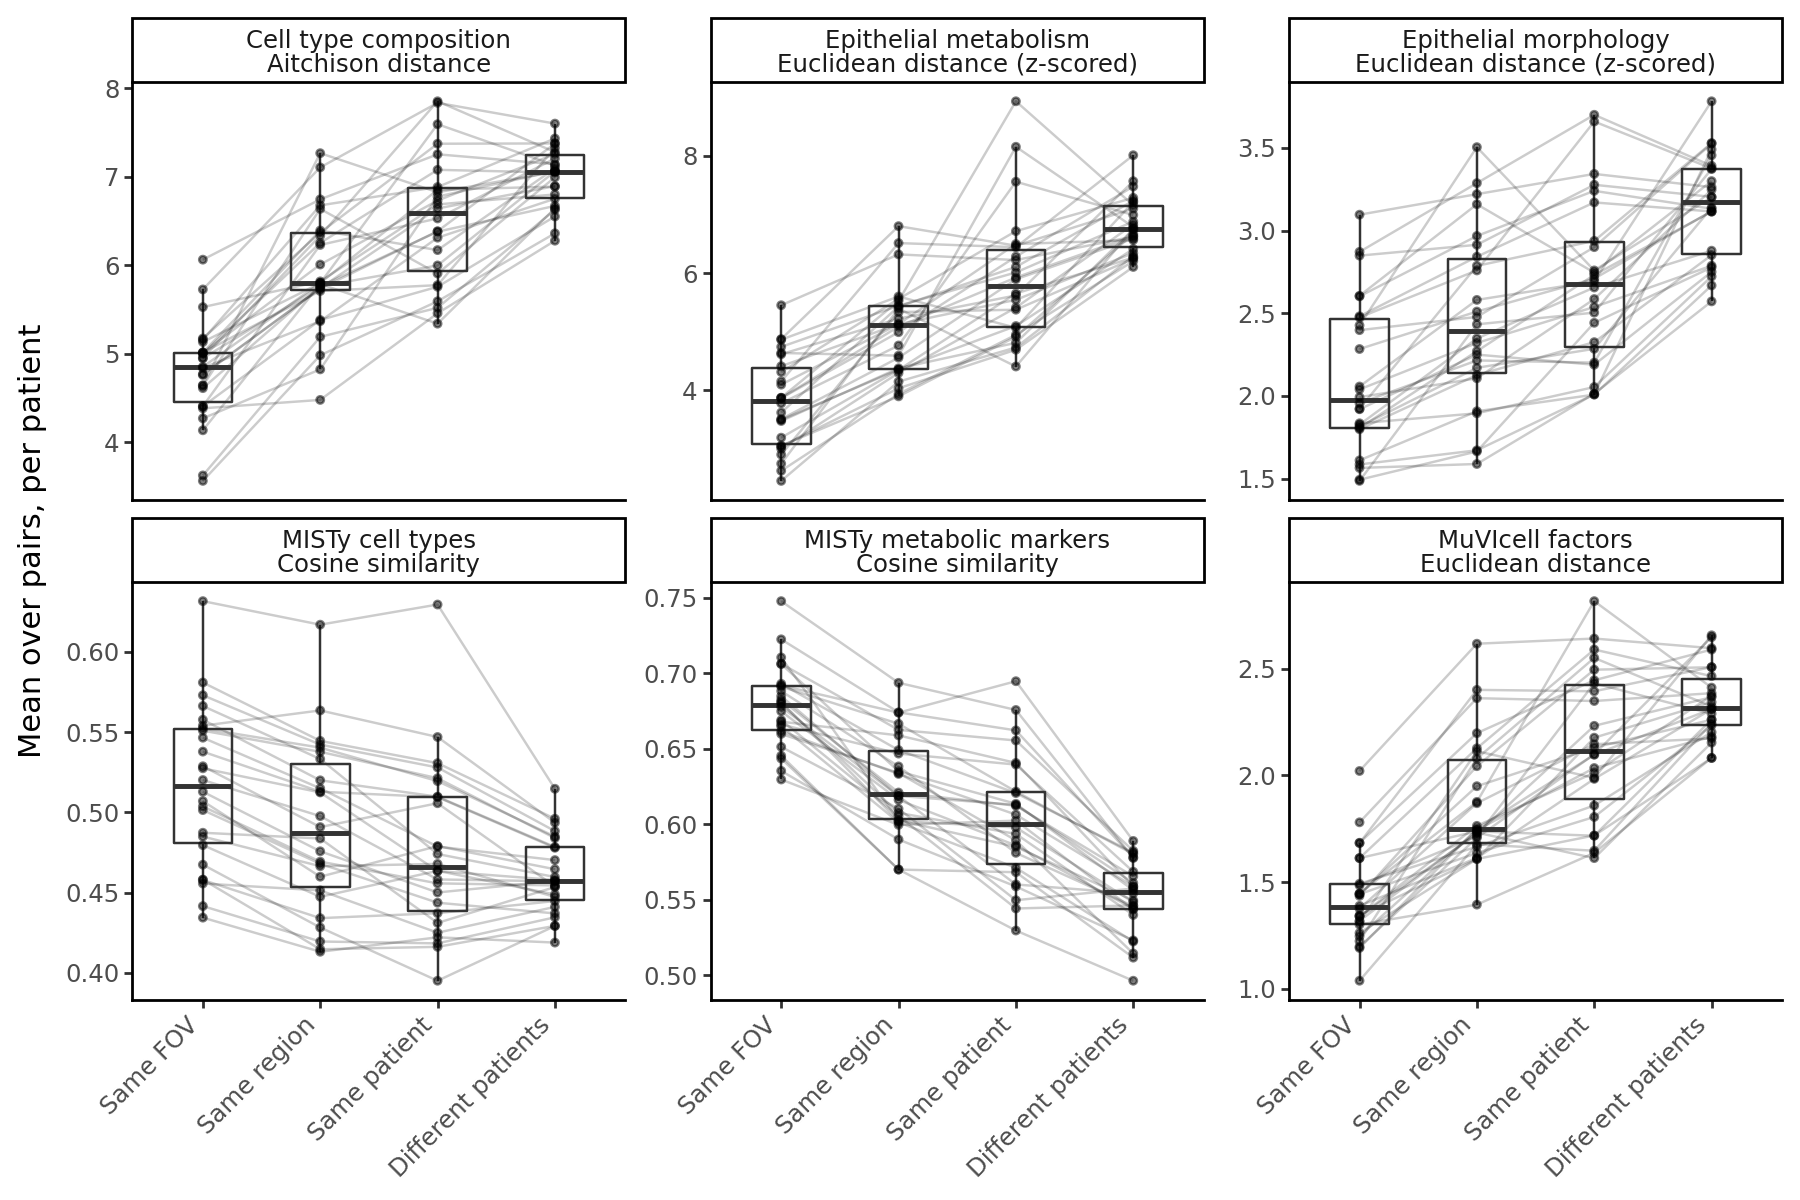

In [46]:
# Per aspect, in the units of its metric: one point per patient, with lines connecting the same patient
gp = (ggplot(per_patient, aes(x="category", y="value"))
      + geom_line(aes(group="patient"), alpha=0.2)
      + geom_boxplot(outlier_shape="", fill="none", width=0.5)
      + geom_point(alpha=0.5, size=1)
      + facet_wrap("~aspect + metric", scales="free_y", ncol=3)
      + labs(x="", y="Mean over pairs, per patient")
      + theme_classic()
      + theme(axis_text_x=element_text(rotation=45, ha="right"),
              figure_size=(9, 6), subplots_adjust={"wspace": 0.3, "hspace": 0.5}))
gp.save(fig_dir + "similarity_per_aspect.pdf")
gp

/home/loan/miniforge3/envs/pam-keras3/lib/python3.11/site-packages/plotnine/ggplot.py:606: PlotnineWarning: Saving 6 x 4 in image.
/home/loan/miniforge3/envs/pam-keras3/lib/python3.11/site-packages/plotnine/ggplot.py:607: PlotnineWarning: Filename: figures/sampling/quadrant_similarity/similarity_percentile_all_aspects.pdf


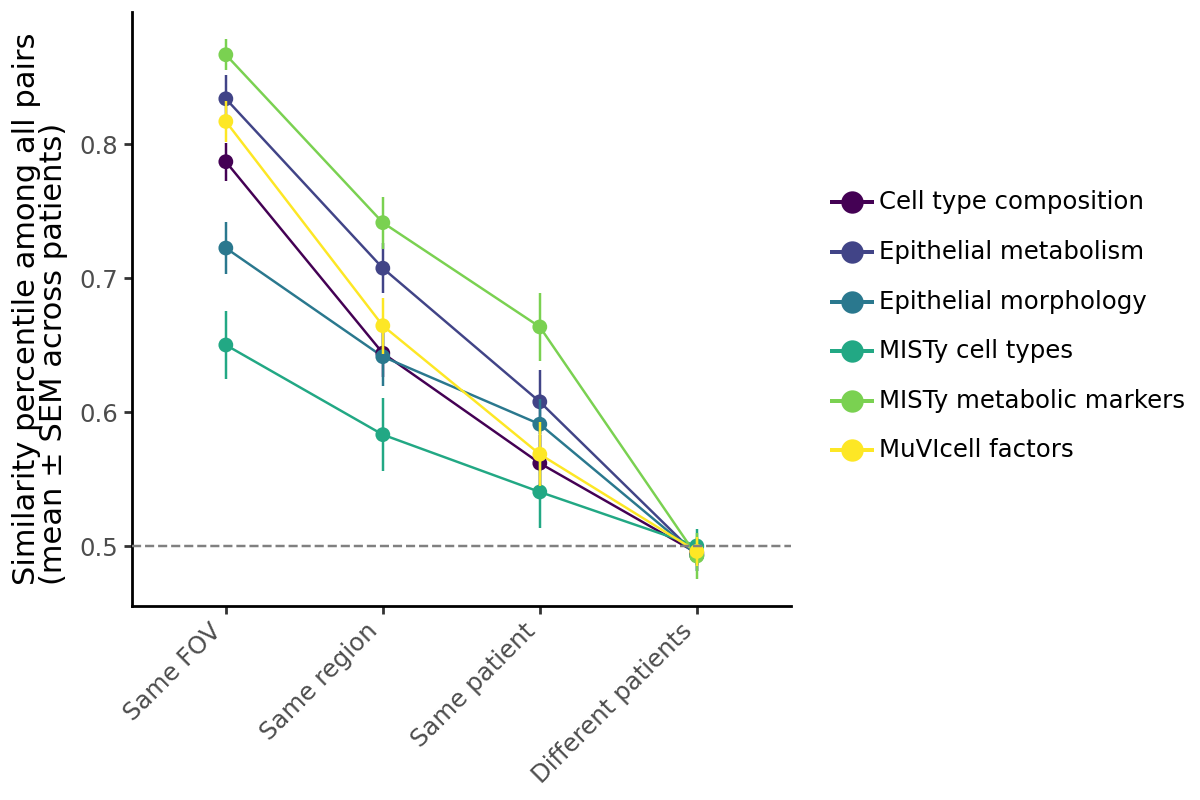

In [47]:
# All aspects on a common scale: mean similarity percentile across patients
summary = (per_patient.groupby(["aspect", "category"], observed=True).similarity_percentile
           .agg(["mean", "sem"]).reset_index())
gp = (ggplot(summary, aes(x="category", y="mean", color="aspect", group="aspect"))
      + geom_line()
      + geom_pointrange(aes(ymin="mean - sem", ymax="mean + sem"))
      + geom_hline(yintercept=0.5, linetype="dashed", color="grey")
      + labs(x="", y="Similarity percentile among all pairs\n(mean ± SEM across patients)", color="")
      + theme_classic()
      + theme(axis_text_x=element_text(rotation=45, ha="right"), figure_size=(6, 4)))
gp.save(fig_dir + "similarity_percentile_all_aspects.pdf")
gp

## Export

In [48]:
pairs.to_csv(data_dir + "quadrant_similarity_pairs.csv", index=False)
per_patient.to_csv(data_dir + "quadrant_similarity_per_patient.csv", index=False)
stats.to_csv(data_dir + "quadrant_similarity_stats.csv")